Eğitim boyutu: (43500, 10)
Test boyutu: (14500, 10)


,örnek sayısı
sinif,
1,34108
2,37
3,132
4,6748
5,2458
6,6
7,11


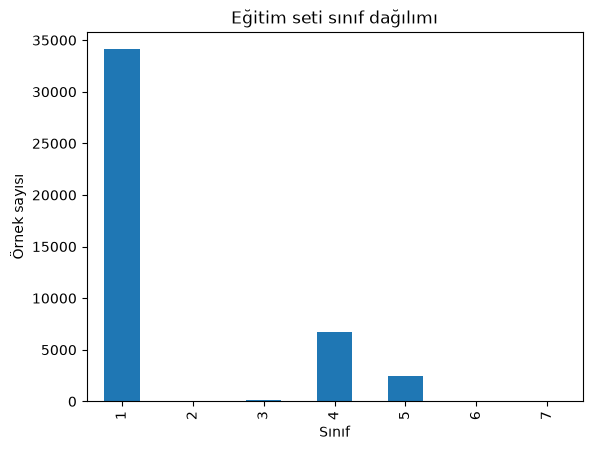

In [1]:
import pandas as pd
import matplotlib.pyplot as plt

# Shuttle dosyalarında başlık satırı yok: 9 öznitelik + 1 sınıf sütunu
sutunlar = [f"A{i}" for i in range(1, 10)] + ["sinif"]

egitim = pd.read_csv("data/shuttle.trn", sep=r"\s+", header=None, names=sutunlar)
test = pd.read_csv("data/shuttle.tst", sep=r"\s+", header=None, names=sutunlar)

print("Eğitim boyutu:", egitim.shape)
print("Test boyutu:", test.shape)

# Sınıf dağılımı (tablo)
dagilim = egitim["sinif"].value_counts().sort_index()
display(dagilim.to_frame("örnek sayısı"))

# Sınıf dağılımı (grafik)
dagilim.plot(kind="bar")
plt.xlabel("Sınıf")
plt.ylabel("Örnek sayısı")
plt.title("Eğitim seti sınıf dağılımı")
plt.show()

In [2]:
import os, random
import numpy as np
import torch
import seaborn as sns

# Tekrarlanabilirlik için sabit seed (ödev şartı)
SEED = 42
random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)

os.makedirs("sekiller", exist_ok=True)
os.makedirs("tablolar", exist_ok=True)

oznitelikler = sutunlar[:-1]
sinif_adlari = {1: "Rad Flow", 2: "Fpv Close", 3: "Fpv Open", 4: "High",
                5: "Bypass", 6: "Bpv Close", 7: "Bpv Open"}

# T1 - Genel özet
t1 = pd.DataFrame({
    "Bilgi": ["Eğitim örneği", "Test örneği", "Öznitelik sayısı", "Sınıf sayısı",
              "Eksik değer (eğitim)", "Eksik değer (test)", "Çoğunluk sınıfı oranı (eğitim)"],
    "Değer": [len(egitim), len(test), len(oznitelikler), egitim["sinif"].nunique(),
              int(egitim.isna().sum().sum()), int(test.isna().sum().sum()),
              f"%{100 * egitim['sinif'].value_counts(normalize=True).max():.2f}"]
})
display(t1)
t1.to_csv("tablolar/T1a_genel_ozet.csv", index=False, encoding="utf-8-sig")

# T1 - Betimsel istatistikler
istat = egitim[oznitelikler].describe().T.round(2)
display(istat)
istat.to_csv("tablolar/T1b_istatistikler.csv", encoding="utf-8-sig")

# T1 - Sınıf dağılımı (eğitim ve test)
sinif_tablo = pd.DataFrame({
    "Sınıf adı": pd.Series(sinif_adlari),
    "Eğitim": egitim["sinif"].value_counts(),
    "Test": test["sinif"].value_counts()
}).fillna(0)
sinif_tablo[["Eğitim", "Test"]] = sinif_tablo[["Eğitim", "Test"]].astype(int)
sinif_tablo["Eğitim (%)"] = (100 * sinif_tablo["Eğitim"] / len(egitim)).round(3)
sinif_tablo["Test (%)"] = (100 * sinif_tablo["Test"] / len(test)).round(3)
display(sinif_tablo)
sinif_tablo.to_csv("tablolar/T1c_sinif_dagilimi.csv", encoding="utf-8-sig")

# T2 - Öznitelik tanımlama tablosu
t2 = pd.DataFrame({
    "Öznitelik": sutunlar,
    "Veri tipi": egitim.dtypes.astype(str).values,
    "Açıklama": ["Zaman"] + ["Sensör ölçümü (adlandırılmamış)"] * 8 + ["Radyatör durumu (hedef, 7 sınıf)"],
    "Min": egitim.min().values,
    "Maks": egitim.max().values
})
display(t2)
t2.to_csv("tablolar/T2_oznitelikler.csv", index=False, encoding="utf-8-sig")


,Bilgi,Değer
0,Eğitim örneği,43500
1,Test örneği,14500
2,Öznitelik sayısı,9
3,Sınıf sayısı,7
4,Eksik değer (eğitim),0
5,Eksik değer (test),0
6,Çoğunluk sınıfı oranı (eğitim),%78.41


,count,mean,std,min,25%,50%,75%,max
A1,43500.0,48.25,12.25,27.0,38.0,45.0,55.0,126.0
A2,43500.0,-0.21,78.14,-4821.0,0.0,0.0,0.0,5075.0
A3,43500.0,85.34,8.91,21.0,79.0,83.0,89.0,149.0
A4,43500.0,0.26,41.00,-3939.0,0.0,0.0,0.0,3830.0
A5,43500.0,34.53,21.70,-188.0,26.0,42.0,46.0,436.0
A6,43500.0,1.30,179.49,-13839.0,-5.0,0.0,5.0,13148.0
A7,43500.0,37.07,13.14,-48.0,31.0,39.0,42.0,105.0
A8,43500.0,50.90,21.46,-353.0,37.0,44.0,60.0,270.0
A9,43500.0,13.96,25.65,-356.0,0.0,2.0,14.0,266.0


,Sınıf adı,Eğitim,Test,Eğitim (%),Test (%)
1,Rad Flow,34108,11478,78.409,79.159
2,Fpv Close,37,13,0.085,0.090
3,Fpv Open,132,39,0.303,0.269
4,High,6748,2155,15.513,14.862
5,Bypass,2458,809,5.651,5.579
6,Bpv Close,6,4,0.014,0.028
7,Bpv Open,11,2,0.025,0.014


,Öznitelik,Veri tipi,Açıklama,Min,Maks
0,A1,int64,Zaman,27,126
1,A2,int64,Sensör ölçümü (adlandırılmamış),-4821,5075
2,A3,int64,Sensör ölçümü (adlandırılmamış),21,149
3,A4,int64,Sensör ölçümü (adlandırılmamış),-3939,3830
4,A5,int64,Sensör ölçümü (adlandırılmamış),-188,436
5,A6,int64,Sensör ölçümü (adlandırılmamış),-13839,13148
6,A7,int64,Sensör ölçümü (adlandırılmamış),-48,105
7,A8,int64,Sensör ölçümü (adlandırılmamış),-353,270
8,A9,int64,Sensör ölçümü (adlandırılmamış),-356,266
9,sinif,int64,"Radyatör durumu (hedef, 7 sınıf)",1,7


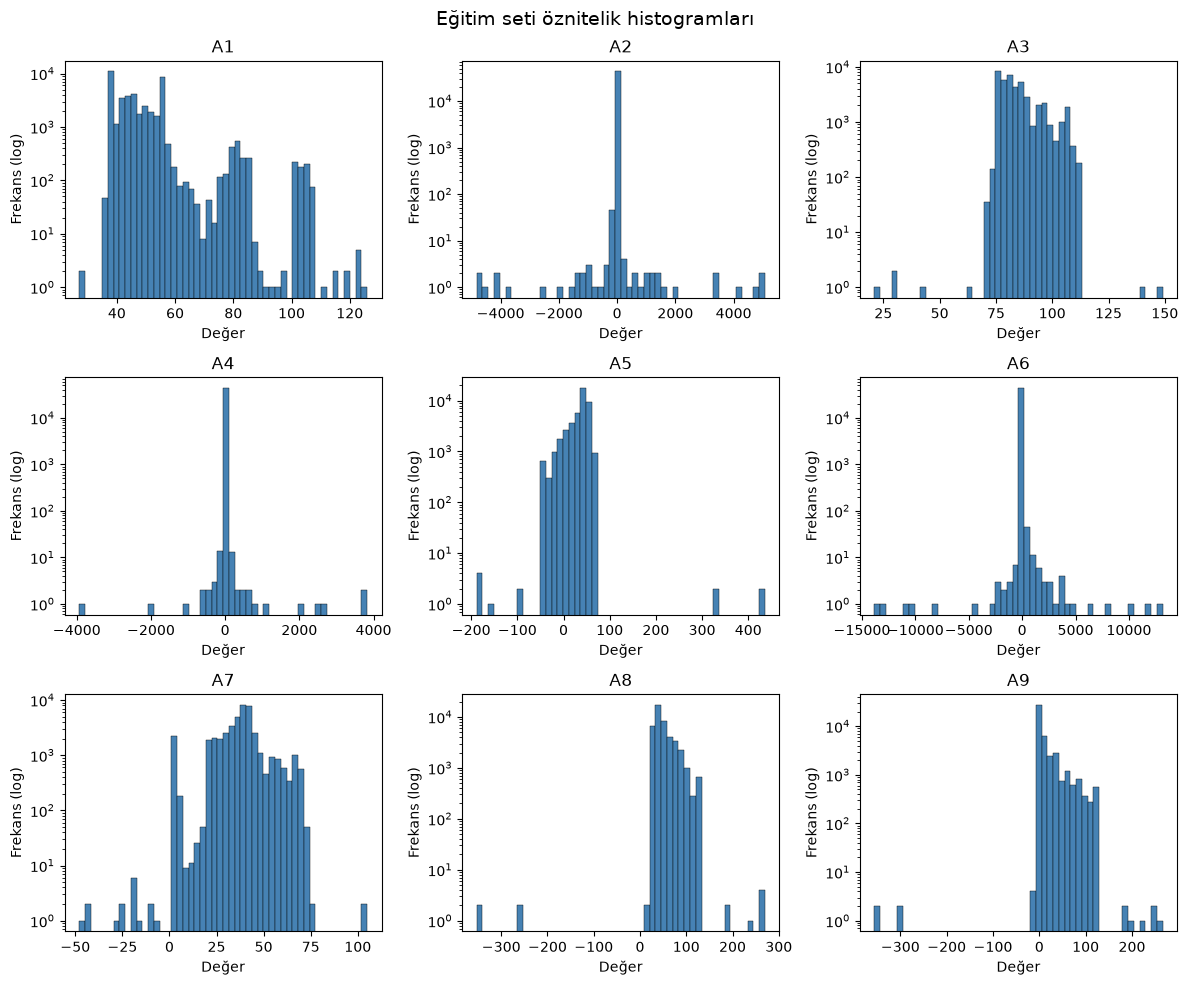

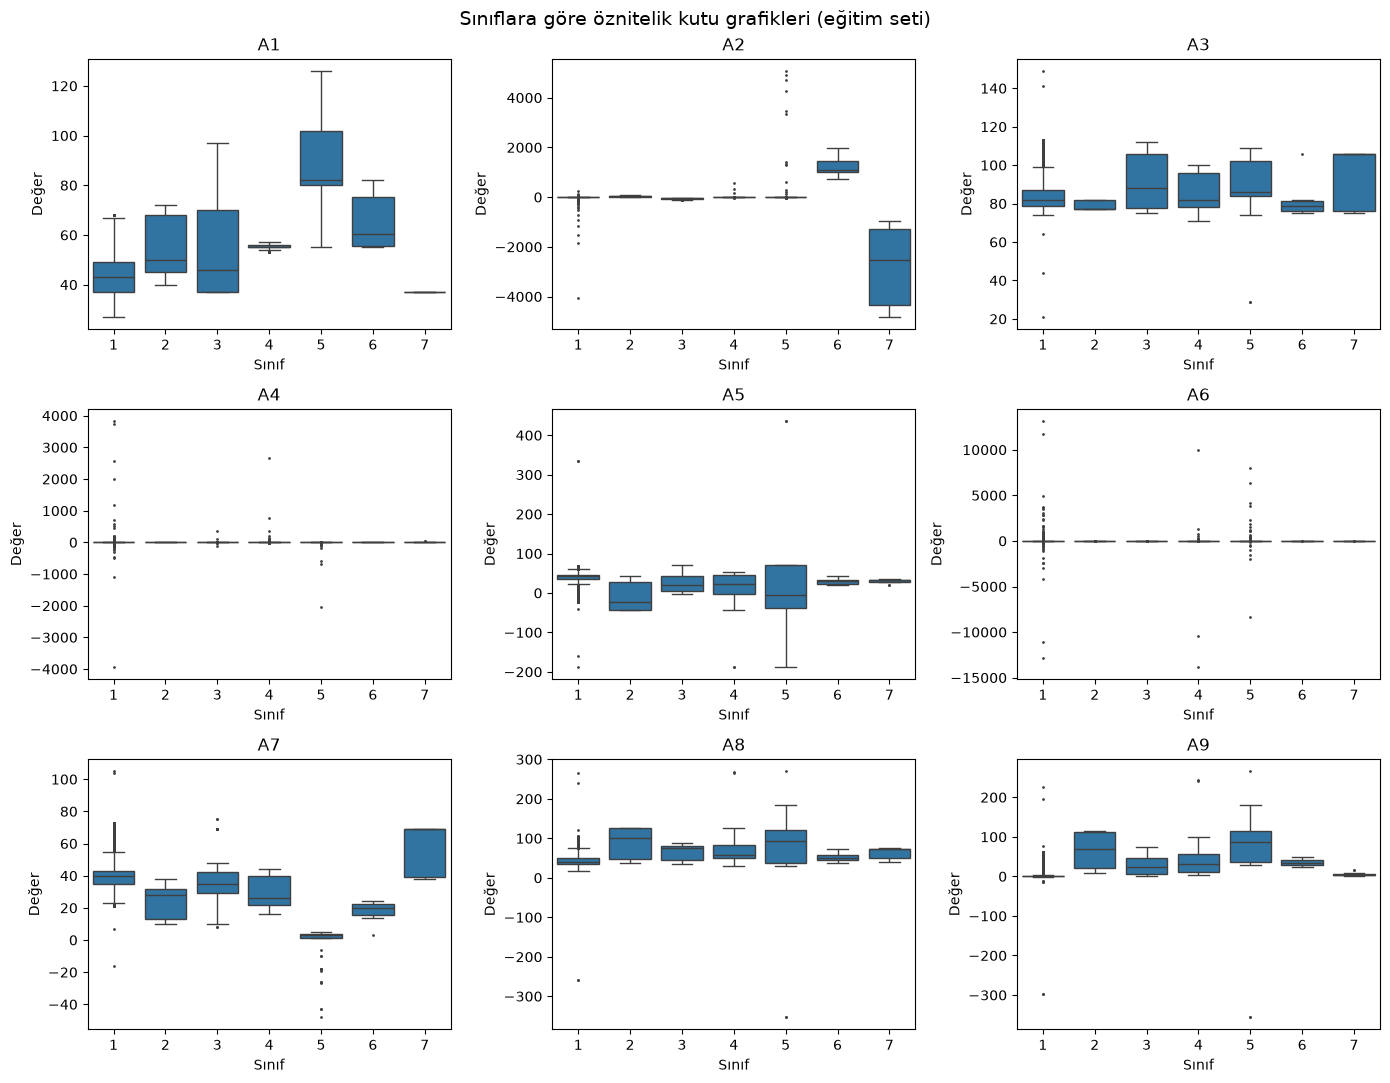

In [3]:
# G1a - Histogramlar (dengesiz dağılım nedeniyle y ekseni logaritmik)
fig, axes = plt.subplots(3, 3, figsize=(12, 10))
for ax, col in zip(axes.flat, oznitelikler):
    ax.hist(egitim[col], bins=50, color="steelblue", edgecolor="black", linewidth=0.3)
    ax.set_yscale("log")
    ax.set_title(col)
    ax.set_xlabel("Değer")
    ax.set_ylabel("Frekans (log)")
fig.suptitle("Eğitim seti öznitelik histogramları", fontsize=14)
plt.tight_layout()
plt.savefig("sekiller/G1a_histogram.png", dpi=300)
plt.show()

# G1b - Sınıflara göre kutu grafikleri
fig, axes = plt.subplots(3, 3, figsize=(14, 11))
for ax, col in zip(axes.flat, oznitelikler):
    sns.boxplot(data=egitim, x="sinif", y=col, ax=ax, fliersize=1)
    ax.set_title(col)
    ax.set_xlabel("Sınıf")
    ax.set_ylabel("Değer")
fig.suptitle("Sınıflara göre öznitelik kutu grafikleri (eğitim seti)", fontsize=14)
plt.tight_layout()
plt.savefig("sekiller/G1b_boxplot.png", dpi=300)
plt.show()


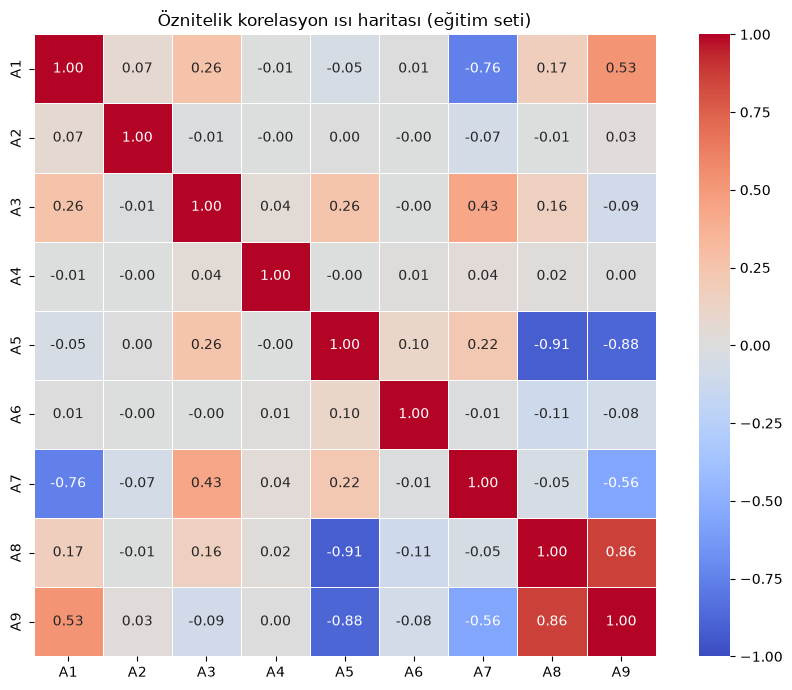

In [4]:
korelasyon = egitim[oznitelikler].corr()

plt.figure(figsize=(9, 7))
sns.heatmap(korelasyon, annot=True, fmt=".2f", cmap="coolwarm",
            vmin=-1, vmax=1, square=True, linewidths=0.5)
plt.title("Öznitelik korelasyon ısı haritası (eğitim seti)")
plt.tight_layout()
plt.savefig("sekiller/G2_korelasyon.png", dpi=300)
plt.show()

korelasyon.round(3).to_csv("tablolar/G2_korelasyon_degerleri.csv", encoding="utf-8-sig")

In [5]:
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler

# Girdi (X) ve hedef (y). Sınıfları 1-7 yerine 0-6 yapıyoruz (PyTorch böyle istiyor)
X = egitim[oznitelikler].values
y = egitim["sinif"].values - 1
X_test = test[oznitelikler].values
y_test = test["sinif"].values - 1

# Eğitimin %20'si doğrulama; sınıf oranları korunarak (stratify)
X_train, X_val, y_train, y_val = train_test_split(
    X, y, test_size=0.2, stratify=y, random_state=SEED)

# Ölçekleme: sadece eğitim verisine göre öğrenilir, diğerlerine aynısı uygulanır
olcekleyici = StandardScaler()
X_train = olcekleyici.fit_transform(X_train)
X_val = olcekleyici.transform(X_val)
X_test = olcekleyici.transform(X_test)

print("Eğitim:", X_train.shape, " Doğrulama:", X_val.shape, " Test:", X_test.shape)

# T3 - Ön işleme adımları
t3 = pd.DataFrame({
    "Adım": ["1", "2", "3", "4", "5"],
    "İşlem": ["Eksik değer kontrolü",
              "Etiket dönüşümü",
              "Eğitim/doğrulama bölmesi",
              "Standartlaştırma (z-skor)",
              "Test seti"],
    "Açıklama": ["Eksik değer bulunmadı, işlem gerekmedi",
                 "Sınıflar 1-7 → 0-6",
                 f"%80 eğitim ({len(X_train)}), %20 doğrulama ({len(X_val)}), tabakalı, seed={SEED}",
                 "Ortalama ve std yalnızca eğitim setinden hesaplandı (veri sızıntısı önlendi)",
                 f"Orijinal UCI test dosyası ({len(X_test)} örnek), yalnızca son değerlendirmede kullanıldı"]
})
display(t3)
t3.to_csv("tablolar/T3_on_isleme.csv", index=False, encoding="utf-8-sig")

Eğitim: (34800, 9)  Doğrulama: (8700, 9)  Test: (14500, 9)


,Adım,İşlem,Açıklama
0,1,Eksik değer kontrolü,"Eksik değer bulunmadı, işlem gerekmedi"
1,2,Etiket dönüşümü,Sınıflar 1-7 → 0-6
2,3,Eğitim/doğrulama bölmesi,"%80 eğitim (34800), %20 doğrulama (8700), taba..."
3,4,Standartlaştırma (z-skor),Ortalama ve std yalnızca eğitim setinden hesap...
4,5,Test seti,"Orijinal UCI test dosyası (14500 örnek), yalnı..."


In [ ]:
import time
import torch.nn as nn
from torch.utils.data import TensorDataset, DataLoader
from sklearn.metrics import f1_score

cihaz = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print("Kullanılan cihaz:", cihaz)

# Numpy dizilerini PyTorch tensörlerine çevir
Xtr_t = torch.tensor(X_train, dtype=torch.float32); ytr_t = torch.tensor(y_train, dtype=torch.long)
Xva_t = torch.tensor(X_val, dtype=torch.float32);   yva_t = torch.tensor(y_val, dtype=torch.long)
Xte_t = torch.tensor(X_test, dtype=torch.float32);  yte_t = torch.tensor(y_test, dtype=torch.long)

# Model: çok katmanlı algılayıcı (MLP)
class MLP(nn.Module):
    def __init__(self, girdi=9, gizli=(64, 32), cikti=7, dropout=0.2):
        super().__init__()
        katmanlar, onceki = [], girdi
        for n in gizli:
            katmanlar += [nn.Linear(onceki, n), nn.ReLU(), nn.Dropout(dropout)]
            onceki = n
        katmanlar.append(nn.Linear(onceki, cikti))
        self.ag = nn.Sequential(*katmanlar)

    def forward(self, x):
        return self.ag(x)

# Bir veri seti üzerinde kayıp, doğruluk ve macro F1 hesapla
def degerlendir(model, X, y, kayip_fn):
    model.eval()
    with torch.no_grad():
        cikti = model(X.to(cihaz))
        kayip = kayip_fn(cikti, y.to(cihaz)).item()
        tahmin = cikti.argmax(1).cpu()
    dogruluk = (tahmin == y).float().mean().item()
    f1 = f1_score(y, tahmin, average="macro", zero_division=0)
    return kayip, dogruluk, f1, tahmin

# Verilen batch büyüklüğüyle modeli sıfırdan eğit
def egit(batch_size, epoch_sayisi=50, lr=1e-3, gizli=(64, 32), dropout=0.2):
    random.seed(SEED); np.random.seed(SEED); torch.manual_seed(SEED)
    g = torch.Generator().manual_seed(SEED)
    yukleyici = DataLoader(TensorDataset(Xtr_t, ytr_t), batch_size=batch_size,
                           shuffle=True, generator=g)
    model = MLP(gizli=gizli, dropout=dropout).to(cihaz)
    optimizer = torch.optim.Adam(model.parameters(), lr=lr)
    kayip_fn = nn.CrossEntropyLoss()

    gecmis = {k: [] for k in ["egitim_kayip", "dogrulama_kayip", "egitim_dogruluk",
                              "dogrulama_dogruluk", "dogrulama_f1", "sure_sn"]}
    for epoch in range(epoch_sayisi):
        model.train()
        t0 = time.perf_counter()
        for xb, yb in yukleyici:
            xb, yb = xb.to(cihaz), yb.to(cihaz)
            optimizer.zero_grad()
            kayip = kayip_fn(model(xb), yb)
            kayip.backward()
            optimizer.step()
        gecmis["sure_sn"].append(time.perf_counter() - t0)

        ek, ed, _, _ = degerlendir(model, Xtr_t, ytr_t, kayip_fn)
        dk, dd, df, _ = degerlendir(model, Xva_t, yva_t, kayip_fn)
        gecmis["egitim_kayip"].append(ek);   gecmis["egitim_dogruluk"].append(ed)
        gecmis["dogrulama_kayip"].append(dk); gecmis["dogrulama_dogruluk"].append(dd)
        gecmis["dogrulama_f1"].append(df)
    return model, gecmis

# Deneme: batch size 64, sadece 5 epoch
model, gecmis = egit(batch_size=64, epoch_sayisi=5)
deneme = pd.DataFrame(gecmis)
deneme.index = deneme.index + 1
deneme.index.name = "epoch"
display(deneme.round(4))

In [6]:
import time
import torch.nn as nn
from torch.utils.data import TensorDataset, DataLoader
from sklearn.metrics import f1_score

cihaz = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print("Kullanılan cihaz:", cihaz)

# Numpy dizilerini PyTorch tensörlerine çevir
Xtr_t = torch.tensor(X_train, dtype=torch.float32); ytr_t = torch.tensor(y_train, dtype=torch.long)
Xva_t = torch.tensor(X_val, dtype=torch.float32);   yva_t = torch.tensor(y_val, dtype=torch.long)
Xte_t = torch.tensor(X_test, dtype=torch.float32);  yte_t = torch.tensor(y_test, dtype=torch.long)

# Model: çok katmanlı algılayıcı (MLP)
class MLP(nn.Module):
    def __init__(self, girdi=9, gizli=(64, 32), cikti=7, dropout=0.2):
        super().__init__()
        katmanlar, onceki = [], girdi
        for n in gizli:
            katmanlar += [nn.Linear(onceki, n), nn.ReLU(), nn.Dropout(dropout)]
            onceki = n
        katmanlar.append(nn.Linear(onceki, cikti))
        self.ag = nn.Sequential(*katmanlar)

    def forward(self, x):
        return self.ag(x)

# Bir veri seti üzerinde kayıp, doğruluk ve macro F1 hesapla
def degerlendir(model, X, y, kayip_fn):
    model.eval()
    with torch.no_grad():
        cikti = model(X.to(cihaz))
        kayip = kayip_fn(cikti, y.to(cihaz)).item()
        tahmin = cikti.argmax(1).cpu()
    dogruluk = (tahmin == y).float().mean().item()
    f1 = f1_score(y, tahmin, average="macro", zero_division=0)
    return kayip, dogruluk, f1, tahmin

# Verilen batch büyüklüğüyle modeli sıfırdan eğit
def egit(batch_size, epoch_sayisi=50, lr=1e-3, gizli=(64, 32), dropout=0.2):
    random.seed(SEED); np.random.seed(SEED); torch.manual_seed(SEED)
    g = torch.Generator().manual_seed(SEED)
    yukleyici = DataLoader(TensorDataset(Xtr_t, ytr_t), batch_size=batch_size,
                           shuffle=True, generator=g)
    model = MLP(gizli=gizli, dropout=dropout).to(cihaz)
    optimizer = torch.optim.Adam(model.parameters(), lr=lr)
    kayip_fn = nn.CrossEntropyLoss()

    gecmis = {k: [] for k in ["egitim_kayip", "dogrulama_kayip", "egitim_dogruluk",
                              "dogrulama_dogruluk", "dogrulama_f1", "sure_sn"]}
    for epoch in range(epoch_sayisi):
        model.train()
        t0 = time.perf_counter()
        for xb, yb in yukleyici:
            xb, yb = xb.to(cihaz), yb.to(cihaz)
            optimizer.zero_grad()
            kayip = kayip_fn(model(xb), yb)
            kayip.backward()
            optimizer.step()
        gecmis["sure_sn"].append(time.perf_counter() - t0)

        ek, ed, _, _ = degerlendir(model, Xtr_t, ytr_t, kayip_fn)
        dk, dd, df, _ = degerlendir(model, Xva_t, yva_t, kayip_fn)
        gecmis["egitim_kayip"].append(ek);   gecmis["egitim_dogruluk"].append(ed)
        gecmis["dogrulama_kayip"].append(dk); gecmis["dogrulama_dogruluk"].append(dd)
        gecmis["dogrulama_f1"].append(df)
    return model, gecmis

# Deneme: batch size 64, sadece 5 epoch
model, gecmis = egit(batch_size=64, epoch_sayisi=5)
deneme = pd.DataFrame(gecmis)
deneme.index = deneme.index + 1
deneme.index.name = "epoch"
display(deneme.round(4))

Kullanılan cihaz: cpu


,egitim_kayip,dogrulama_kayip,egitim_dogruluk,dogrulama_dogruluk,dogrulama_f1,sure_sn
epoch,,,,,,
1,0.0756,0.0737,0.9878,0.9876,0.4221,1.3158
2,0.0453,0.0436,0.9946,0.9948,0.5211,1.3746
3,0.0373,0.0397,0.9947,0.9947,0.5210,1.3986
4,0.0320,0.0379,0.9947,0.9951,0.5691,1.3399
5,0.0275,0.0334,0.9953,0.9954,0.5215,1.4646


In [7]:
batch_listesi = [16, 32, 64, 128, 256, 512, 1024]
EPOCH = 50
kayip_fn = nn.CrossEntropyLoss()

sonuclar = {}   # her batch size için epoch epoch geçmiş
modeller = {}   # eğitilmiş modeller (karışıklık matrisi için lazım olacak)
ozet = []

for bs in batch_listesi:
    print(f"Batch size {bs:>4} eğitiliyor...", end=" ", flush=True)
    model, gecmis = egit(batch_size=bs, epoch_sayisi=EPOCH)
    sonuclar[bs], modeller[bs] = gecmis, model

    # Epoch geçmişini kaydet
    pd.DataFrame(gecmis, index=range(1, EPOCH + 1)).to_csv(
        f"tablolar/gecmis_bs{bs}.csv", index_label="epoch", encoding="utf-8-sig")

    # Test seti üzerinde değerlendirme (model hiç görmedi)
    test_kayip, test_dogruluk, test_f1, _ = degerlendir(model, Xte_t, yte_t, kayip_fn)
    toplam_sure = sum(gecmis["sure_sn"])

    ozet.append({
        "Batch size": bs,
        "Güncelleme/epoch": int(np.ceil(len(Xtr_t) / bs)),
        "Eğitim doğruluğu": gecmis["egitim_dogruluk"][-1],
        "Doğrulama doğruluğu": gecmis["dogrulama_dogruluk"][-1],
        "Doğrulama F1": gecmis["dogrulama_f1"][-1],
        "Test doğruluğu": test_dogruluk,
        "Test macro F1": test_f1,
        "Test kaybı": test_kayip,
        "Genelleme farkı (eğitim − test)": gecmis["egitim_dogruluk"][-1] - test_dogruluk,
        "En iyi doğr. kaybı epoch'u": int(np.argmin(gecmis["dogrulama_kayip"])) + 1,
        "Ort. epoch süresi (sn)": np.mean(gecmis["sure_sn"]),
        "Toplam eğitim süresi (sn)": toplam_sure,
        "Örnek/sn": len(Xtr_t) * EPOCH / toplam_sure,
    })
    print(f"bitti ({toplam_sure:.0f} sn) → test doğruluğu {test_dogruluk:.4f}, test F1 {test_f1:.4f}")

# T6 - Ana performans tablosu
t6 = pd.DataFrame(ozet).set_index("Batch size")
display(t6.round(4))
t6.round(4).to_csv("tablolar/T6_performans_ozeti.csv", encoding="utf-8-sig")

Batch size   16 eğitiliyor... bitti (186 sn) → test doğruluğu 0.9992, test F1 0.8337
Batch size   32 eğitiliyor... bitti (106 sn) → test doğruluğu 0.9992, test F1 0.7896
Batch size   64 eğitiliyor... bitti (65 sn) → test doğruluğu 0.9991, test F1 0.8427
Batch size  128 eğitiliyor... bitti (44 sn) → test doğruluğu 0.9979, test F1 0.6341
Batch size  256 eğitiliyor... bitti (35 sn) → test doğruluğu 0.9974, test F1 0.6931
Batch size  512 eğitiliyor... bitti (29 sn) → test doğruluğu 0.9968, test F1 0.6327
Batch size 1024 eğitiliyor... bitti (27 sn) → test doğruluğu 0.9960, test F1 0.5611


,Güncelleme/epoch,Eğitim doğruluğu,Doğrulama doğruluğu,Doğrulama F1,Test doğruluğu,Test macro F1,Test kaybı,Genelleme farkı (eğitim − test),En iyi doğr. kaybı epoch'u,Ort. epoch süresi (sn),Toplam eğitim süresi (sn),Örnek/sn
Batch size,,,,,,,,,,,,
16,2175,0.9993,0.9990,0.8266,0.9992,0.8337,0.0061,0.0001,35,3.7156,185.7802,9365.9082
32,1088,0.9992,0.9989,0.8314,0.9992,0.7896,0.0053,0.0001,36,2.1190,105.9479,16423.1595
64,544,0.9991,0.9986,0.8955,0.9991,0.8427,0.0206,-0.0000,50,1.2942,64.7097,26889.3060
128,272,0.9981,0.9970,0.7439,0.9979,0.6341,0.0223,0.0003,43,0.8766,43.8283,39700.4030
256,136,0.9974,0.9967,0.7364,0.9974,0.6931,0.0246,0.0001,47,0.6905,34.5238,50400.0027
512,68,0.9970,0.9963,0.7165,0.9968,0.6327,0.0338,0.0002,45,0.5773,28.8648,60280.9867
1024,34,0.9960,0.9957,0.6848,0.9960,0.5611,0.0374,0.0000,43,0.5309,26.5441,65551.2141


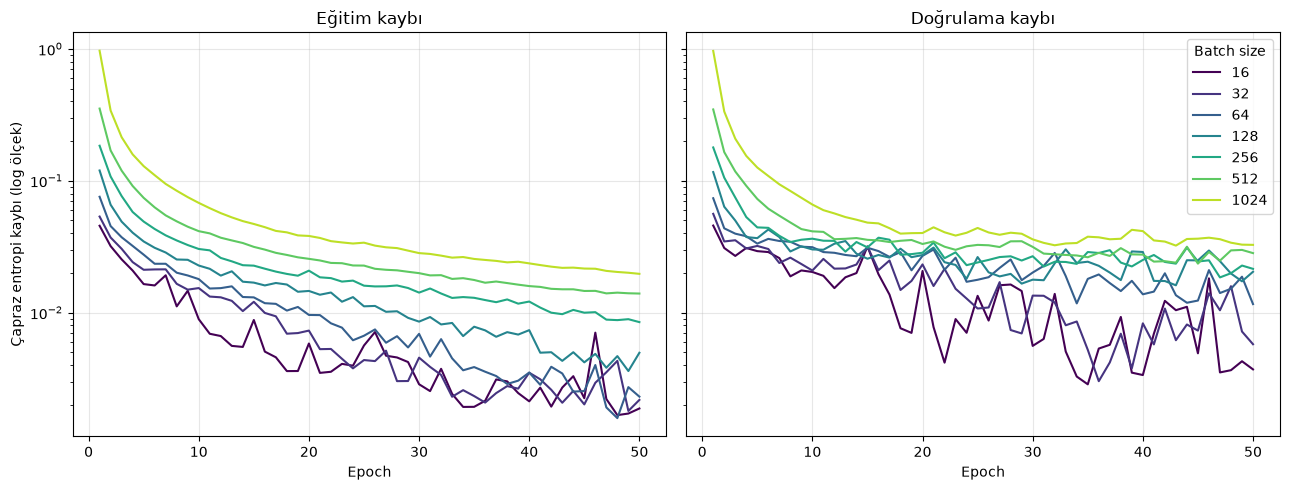

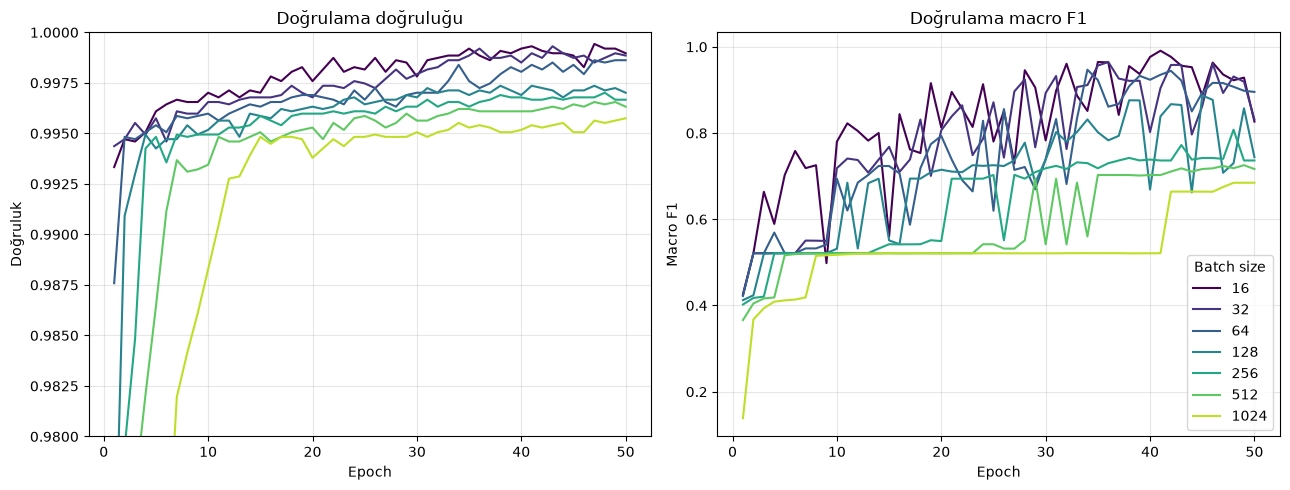

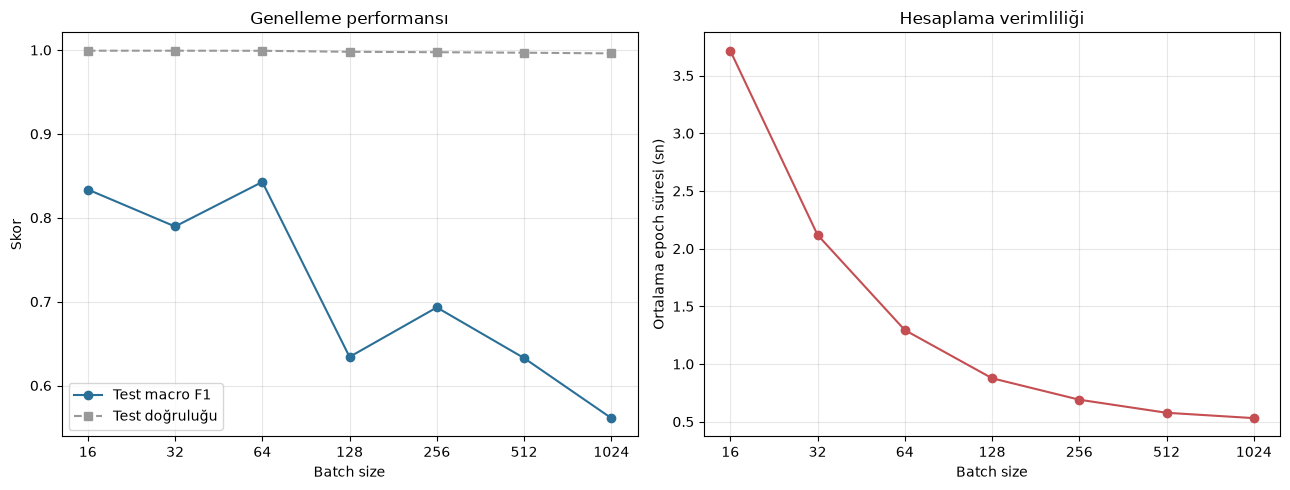

In [8]:
batch_listesi = [16, 32, 64, 128, 256, 512, 1024]
gecmisler = {bs: pd.read_csv(f"tablolar/gecmis_bs{bs}.csv", encoding="utf-8-sig") for bs in batch_listesi}
t6 = pd.read_csv("tablolar/T6_performans_ozeti.csv", encoding="utf-8-sig", index_col=0)

renkler = plt.cm.viridis(np.linspace(0, 0.9, len(batch_listesi)))  # küçük batch koyu, büyük batch açık

# G4 - Kayıp eğrileri
fig, axes = plt.subplots(1, 2, figsize=(13, 5), sharey=True)
for bs, renk in zip(batch_listesi, renkler):
    g = gecmisler[bs]
    axes[0].plot(g["epoch"], g["egitim_kayip"], color=renk, label=f"{bs}")
    axes[1].plot(g["epoch"], g["dogrulama_kayip"], color=renk, label=f"{bs}")
for ax, baslik in zip(axes, ["Eğitim kaybı", "Doğrulama kaybı"]):
    ax.set_yscale("log")
    ax.set_title(baslik)
    ax.set_xlabel("Epoch")
    ax.grid(alpha=0.3)
axes[0].set_ylabel("Çapraz entropi kaybı (log ölçek)")
axes[1].legend(title="Batch size")
plt.tight_layout()
plt.savefig("sekiller/G4_kayip_egrileri.png", dpi=300)
plt.show()

# G5 - Doğrulama doğruluğu ve F1 eğrileri
fig, axes = plt.subplots(1, 2, figsize=(13, 5))
for bs, renk in zip(batch_listesi, renkler):
    g = gecmisler[bs]
    axes[0].plot(g["epoch"], g["dogrulama_dogruluk"], color=renk, label=f"{bs}")
    axes[1].plot(g["epoch"], g["dogrulama_f1"], color=renk, label=f"{bs}")
axes[0].set_title("Doğrulama doğruluğu")
axes[0].set_ylim(0.98, 1.0)
axes[0].set_ylabel("Doğruluk")
axes[1].set_title("Doğrulama macro F1")
axes[1].set_ylabel("Macro F1")
for ax in axes:
    ax.set_xlabel("Epoch")
    ax.grid(alpha=0.3)
axes[1].legend(title="Batch size")
plt.tight_layout()
plt.savefig("sekiller/G5_dogruluk_f1_egrileri.png", dpi=300)
plt.show()

# G6 - Batch büyüklüğüne göre karşılaştırma
fig, axes = plt.subplots(1, 2, figsize=(13, 5))
x = t6.index.values
axes[0].plot(x, t6["Test macro F1"], "o-", color="#2a6f97", label="Test macro F1")
axes[0].plot(x, t6["Test doğruluğu"], "s--", color="#999999", label="Test doğruluğu")
axes[0].set_ylabel("Skor")
axes[0].set_title("Genelleme performansı")
axes[0].legend()
axes[1].plot(x, t6["Ort. epoch süresi (sn)"], "o-", color="#c44e52")
axes[1].set_ylabel("Ortalama epoch süresi (sn)")
axes[1].set_title("Hesaplama verimliliği")
for ax in axes:
    ax.set_xscale("log", base=2)
    ax.set_xticks(x)
    ax.set_xticklabels(x)
    ax.set_xlabel("Batch size")
    ax.grid(alpha=0.3)
plt.tight_layout()
plt.savefig("sekiller/G6_batch_karsilastirma.png", dpi=300)
plt.show()

Batch 64 → test doğruluğu: 0.9991, test macro F1: 0.8427


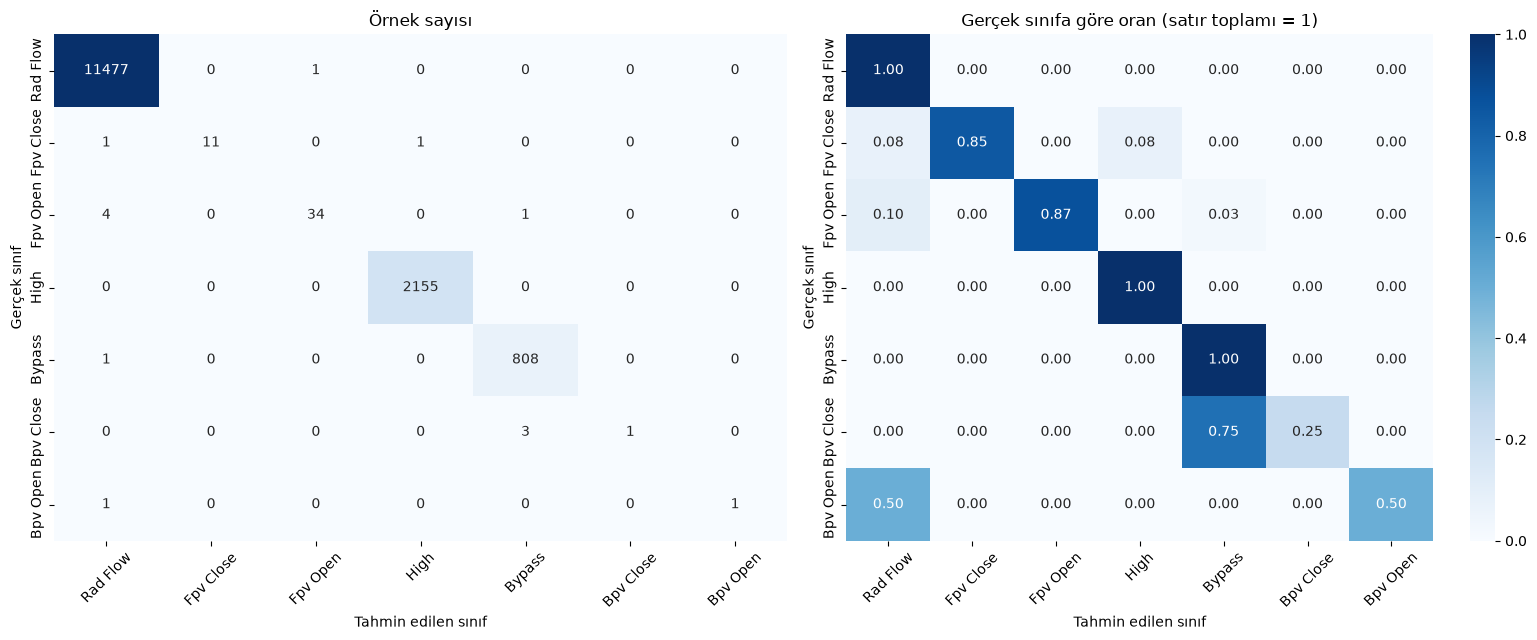

,Kesinlik (precision),Duyarlılık (recall),F1,Test örneği
Rad Flow,0.9994,0.9999,0.9997,11478.0000
Fpv Close,1.0000,0.8462,0.9167,13.0000
Fpv Open,0.9714,0.8718,0.9189,39.0000
High,0.9995,1.0000,0.9998,2155.0000
Bypass,0.9951,0.9988,0.9969,809.0000
Bpv Close,1.0000,0.2500,0.4000,4.0000
Bpv Open,1.0000,0.5000,0.6667,2.0000
accuracy,0.9991,0.9991,0.9991,0.9991
macro avg,0.9951,0.7809,0.8427,14500.0000
weighted avg,0.9991,0.9991,0.9990,14500.0000


Toplam 13 hatalı tahmin (test setinin %0.09'si)


,Test satırı,A1,A2,A3,A4,A5,A6,A7,A8,A9,Gerçek sınıf,Tahmin,Güven
922,922,37,-70,105,0,36,-1,68,69,0,Rad Flow,Fpv Open,0.574
2981,2981,37,-1063,106,-1,34,-2,69,72,4,Bpv Open,Rad Flow,0.688
5058,5058,37,-37,106,-3,34,-6,69,72,4,Fpv Open,Rad Flow,0.664
7519,7519,45,-27,77,-2,44,-3,32,34,2,Fpv Open,Rad Flow,0.561
7586,7586,45,-98,81,0,44,0,36,37,2,Fpv Open,Rad Flow,0.736
7964,7964,79,1963,88,0,44,0,9,44,34,Bpv Close,Bypass,0.746
8185,8185,57,92,80,0,34,0,23,46,24,Fpv Close,High,0.990
9230,9230,91,3049,106,-4,36,1,15,69,54,Bpv Close,Bypass,0.880
10307,10307,79,-1,83,-10,-32,-26739,4,117,112,Bypass,Rad Flow,1.000
11394,11394,82,2561,106,-4,34,-20,24,72,48,Bpv Close,Bypass,0.762


In [9]:
from sklearn.metrics import confusion_matrix, classification_report

kayip_fn = nn.CrossEntropyLoss()

# En iyi model: batch size 64 (hafızada yoksa yeniden eğitilir, ~1 dakika)
if "modeller" in globals() and 64 in modeller:
    en_iyi = modeller[64]
else:
    print("Model hafızada yok, batch 64 yeniden eğitiliyor...")
    en_iyi, _ = egit(batch_size=64, epoch_sayisi=50)

_, test_dogruluk, test_f1, tahmin = degerlendir(en_iyi, Xte_t, yte_t, kayip_fn)
tahmin = tahmin.numpy()
print(f"Batch 64 → test doğruluğu: {test_dogruluk:.4f}, test macro F1: {test_f1:.4f}")

etiketler = list(range(7))
adlar = [sinif_adlari[i + 1] for i in etiketler]

# G7 - Karışıklık matrisi (sayı ve oran)
cm = confusion_matrix(y_test, tahmin, labels=etiketler)
cm_oran = cm / cm.sum(axis=1, keepdims=True)

fig, axes = plt.subplots(1, 2, figsize=(16, 6.5))
sns.heatmap(cm, annot=True, fmt="d", cmap="Blues", cbar=False,
            xticklabels=adlar, yticklabels=adlar, ax=axes[0])
axes[0].set_title("Örnek sayısı")
sns.heatmap(cm_oran, annot=True, fmt=".2f", cmap="Blues", vmin=0, vmax=1,
            xticklabels=adlar, yticklabels=adlar, ax=axes[1])
axes[1].set_title("Gerçek sınıfa göre oran (satır toplamı = 1)")
for ax in axes:
    ax.set_xlabel("Tahmin edilen sınıf")
    ax.set_ylabel("Gerçek sınıf")
    ax.tick_params(axis="x", rotation=45)
plt.tight_layout()
plt.savefig("sekiller/G7_karisiklik_matrisi.png", dpi=300)
plt.show()

# T10a - Sınıf bazında başarı
rapor = classification_report(y_test, tahmin, labels=etiketler, target_names=adlar,
                              output_dict=True, zero_division=0)
t10a = pd.DataFrame(rapor).T.round(4)
t10a = t10a.rename(columns={"precision": "Kesinlik (precision)", "recall": "Duyarlılık (recall)",
                            "f1-score": "F1", "support": "Test örneği"})
display(t10a)
t10a.to_csv("tablolar/T10a_sinif_bazinda_basari.csv", encoding="utf-8-sig")

# T10b - Yanlış tahmin edilen örnekler
en_iyi.eval()
with torch.no_grad():
    olasilik = torch.softmax(en_iyi(Xte_t.to(cihaz)), dim=1).cpu().numpy()

hatali = np.where(tahmin != y_test)[0]
t10b = test.iloc[hatali][oznitelikler].copy()
t10b.insert(0, "Test satırı", hatali)
t10b["Gerçek sınıf"] = [sinif_adlari[s + 1] for s in y_test[hatali]]
t10b["Tahmin"] = [sinif_adlari[s + 1] for s in tahmin[hatali]]
t10b["Güven"] = olasilik[hatali, tahmin[hatali]].round(3)
print(f"Toplam {len(hatali)} hatalı tahmin (test setinin %{100 * len(hatali) / len(y_test):.2f}'si)")
display(t10b)
t10b.to_csv("tablolar/T10b_hatali_tahminler.csv", index=False, encoding="utf-8-sig")

In [10]:
from sklearn.utils.class_weight import compute_class_weight
from sklearn.metrics import recall_score

# Ablasyon için esnek eğitim fonksiyonu (batch size 64, 50 epoch)
def egit_ablasyon(X_eg, y_eg, X_te, batch_size=64, epoch_sayisi=50, lr=1e-3,
                  gizli=(64, 32), dropout=0.2, sinif_agirlikli=False):
    random.seed(SEED); np.random.seed(SEED); torch.manual_seed(SEED)
    g = torch.Generator().manual_seed(SEED)
    yukleyici = DataLoader(TensorDataset(X_eg, y_eg), batch_size=batch_size,
                           shuffle=True, generator=g)
    model = MLP(gizli=gizli, dropout=dropout).to(cihaz)
    optimizer = torch.optim.Adam(model.parameters(), lr=lr)

    if sinif_agirlikli:   # az örnekli sınıfların hatası daha çok cezalandırılır
        w = compute_class_weight("balanced", classes=np.arange(7), y=y_eg.numpy())
        kayip_fn = nn.CrossEntropyLoss(weight=torch.tensor(w, dtype=torch.float32).to(cihaz))
    else:
        kayip_fn = nn.CrossEntropyLoss()

    t0 = time.perf_counter()
    for epoch in range(epoch_sayisi):
        model.train()
        for xb, yb in yukleyici:
            xb, yb = xb.to(cihaz), yb.to(cihaz)
            optimizer.zero_grad()
            kayip_fn(model(xb), yb).backward()
            optimizer.step()
    sure = time.perf_counter() - t0

    model.eval()
    with torch.no_grad():
        tahmin = model(X_te.to(cihaz)).argmax(1).cpu().numpy()
    parametre = sum(p.numel() for p in model.parameters())
    return tahmin, sure, parametre

# Ölçeklenmemiş (ham) veri - A5 için
Xtr_ham = torch.tensor(olcekleyici.inverse_transform(X_train), dtype=torch.float32)
Xte_ham = torch.tensor(test[oznitelikler].values, dtype=torch.float32)

konfigurasyonlar = [
    ("A0", "Temel model (64-32, dropout 0,2)", dict()),
    ("A1", "+ Sınıf ağırlıklandırma",          dict(sinif_agirlikli=True)),
    ("A2", "Dropout yok",                      dict(dropout=0.0)),
    ("A3", "Tek gizli katman (64)",            dict(gizli=(64,))),
    ("A4", "Daha geniş ağ (128-64)",           dict(gizli=(128, 64))),
    ("A5", "Ölçekleme yok (ham veri)",         dict(ham=True)),
]

satirlar = []
for kod, aciklama, ayar in konfigurasyonlar:
    print(f"{kod} - {aciklama} eğitiliyor...", end=" ", flush=True)
    ham = ayar.pop("ham", False)
    X_eg, X_te = (Xtr_ham, Xte_ham) if ham else (Xtr_t, Xte_t)
    tahmin, sure, parametre = egit_ablasyon(X_eg, ytr_t, X_te, **ayar)

    dogruluk = (tahmin == y_test).mean()
    f1 = f1_score(y_test, tahmin, average="macro", zero_division=0)
    duyarlilik = recall_score(y_test, tahmin, average="macro", zero_division=0)
    satirlar.append({"Kod": kod, "Konfigürasyon": aciklama,
                     "Test doğruluğu": dogruluk, "Test macro F1": f1,
                     "Macro duyarlılık": duyarlilik, "Hatalı tahmin": int((tahmin != y_test).sum()),
                     "Parametre sayısı": parametre, "Eğitim süresi (sn)": sure})
    print(f"bitti ({sure:.0f} sn) → F1 {f1:.4f}")

t7 = pd.DataFrame(satirlar).set_index("Kod")
t7["ΔF1 (A0'a göre)"] = t7["Test macro F1"] - t7.loc["A0", "Test macro F1"]
display(t7.round(4))
t7.round(4).to_csv("tablolar/T7_ablasyon.csv", encoding="utf-8-sig")

A0 - Temel model (64-32, dropout 0,2) eğitiliyor... bitti (65 sn) → F1 0.8427
A1 - + Sınıf ağırlıklandırma eğitiliyor... bitti (65 sn) → F1 0.8543
A2 - Dropout yok eğitiliyor... bitti (58 sn) → F1 0.8867
A3 - Tek gizli katman (64) eğitiliyor... bitti (52 sn) → F1 0.8501
A4 - Daha geniş ağ (128-64) eğitiliyor... bitti (72 sn) → F1 0.6925
A5 - Ölçekleme yok (ham veri) eğitiliyor... bitti (66 sn) → F1 0.6863


,Konfigürasyon,Test doğruluğu,Test macro F1,Macro duyarlılık,Hatalı tahmin,Parametre sayısı,Eğitim süresi (sn),ΔF1 (A0'a göre)
Kod,,,,,,,,
A0,"Temel model (64-32, dropout 0,2)",0.9991,0.8427,0.7809,13,2951,65.1697,0.0000
A1,+ Sınıf ağırlıklandırma,0.9981,0.8543,0.9991,28,2951,65.1387,0.0117
A2,Dropout yok,0.9992,0.8867,0.8240,11,2951,58.1474,0.0441
A3,Tek gizli katman (64),0.9986,0.8501,0.8258,20,1095,52.3410,0.0074
A4,Daha geniş ağ (128-64),0.9990,0.6925,0.6811,15,9991,71.5048,-0.1502
A5,Ölçekleme yok (ham veri),0.9981,0.6863,0.6802,28,2951,65.9271,-0.1564


In [1]:
import os, platform
import pandas as pd, numpy as np, torch, sklearn, matplotlib, seaborn as sns
import psutil

os.makedirs("tablolar", exist_ok=True); os.makedirs("sekiller", exist_ok=True)

# T4 - Model hiperparametre tablosu (tam konfigürasyon)
t4 = pd.DataFrame([
    ("Model tipi", "Çok katmanlı algılayıcı (MLP)"),
    ("Girdi boyutu", "9 öznitelik (A1–A9)"),
    ("Gizli katmanlar", "2 katman: 64 ve 32 nöron"),
    ("Çıktı boyutu", "7 sınıf"),
    ("Aktivasyon fonksiyonu", "ReLU"),
    ("Dropout oranı", "0,2 (her gizli katmandan sonra)"),
    ("Toplam parametre sayısı", "2.951"),
    ("Kayıp fonksiyonu", "Çapraz entropi (cross-entropy)"),
    ("Optimizasyon algoritması", "Adam"),
    ("Öğrenme oranı", "0,001 (sabit)"),
    ("Epoch sayısı", "50"),
    ("Batch büyüklükleri (deney değişkeni)", "16, 32, 64, 128, 256, 512, 1024"),
    ("Veri karıştırma", "Her epoch'ta (shuffle=True)"),
    ("Ön işleme", "Z-skor standartlaştırma (yalnızca eğitim setiyle)"),
    ("Eğitim / doğrulama / test", "34.800 / 8.700 / 14.500 örnek"),
    ("Değerlendirme metrikleri", "Doğruluk, macro F1, macro duyarlılık, epoch süresi"),
    ("Rastgelelik tohumu (seed)", "42"),
], columns=["Hiperparametre", "Değer"])
display(t4)
t4.to_csv("tablolar/T4_hiperparametreler.csv", index=False, encoding="utf-8-sig")

# T5 - Hesaplama ortamı tablosu
t5 = pd.DataFrame([
    ("İşletim sistemi", f"{platform.system()} {platform.release()} ({platform.version()})"),
    ("İşlemci (CPU)", platform.processor()),
    ("Mantıksal çekirdek sayısı", os.cpu_count()),
    ("Bellek (RAM)", f"{psutil.virtual_memory().total / 1024**3:.1f} GB"),
    ("GPU", torch.cuda.get_device_name(0) if torch.cuda.is_available() else "Kullanılmadı (yalnızca CPU)"),
    ("Python", platform.python_version()),
    ("PyTorch", torch.__version__),
    ("NumPy", np.__version__),
    ("Pandas", pd.__version__),
    ("Scikit-learn", sklearn.__version__),
    ("Matplotlib", matplotlib.__version__),
    ("Seaborn", sns.__version__),
    ("Geliştirme ortamı", "VS Code + Jupyter Notebook"),
], columns=["Bileşen", "Değer"])
display(t5)
t5.to_csv("tablolar/T5_hesaplama_ortami.csv", index=False, encoding="utf-8-sig")

,Hiperparametre,Değer
0,Model tipi,Çok katmanlı algılayıcı (MLP)
1,Girdi boyutu,9 öznitelik (A1–A9)
2,Gizli katmanlar,2 katman: 64 ve 32 nöron
3,Çıktı boyutu,7 sınıf
4,Aktivasyon fonksiyonu,ReLU
5,Dropout oranı,"0,2 (her gizli katmandan sonra)"
6,Toplam parametre sayısı,2.951
7,Kayıp fonksiyonu,Çapraz entropi (cross-entropy)
8,Optimizasyon algoritması,Adam
9,Öğrenme oranı,"0,001 (sabit)"


,Bileşen,Değer
0,İşletim sistemi,Windows 10 (10.0.19045)
1,İşlemci (CPU),"Intel64 Family 6 Model 165 Stepping 2, Genuine..."
2,Mantıksal çekirdek sayısı,12
3,Bellek (RAM),31.9 GB
4,GPU,Kullanılmadı (yalnızca CPU)
5,Python,3.11.7
6,PyTorch,2.15.0+cpu
7,NumPy,2.4.6
8,Pandas,3.1.1
9,Scikit-learn,1.9.1


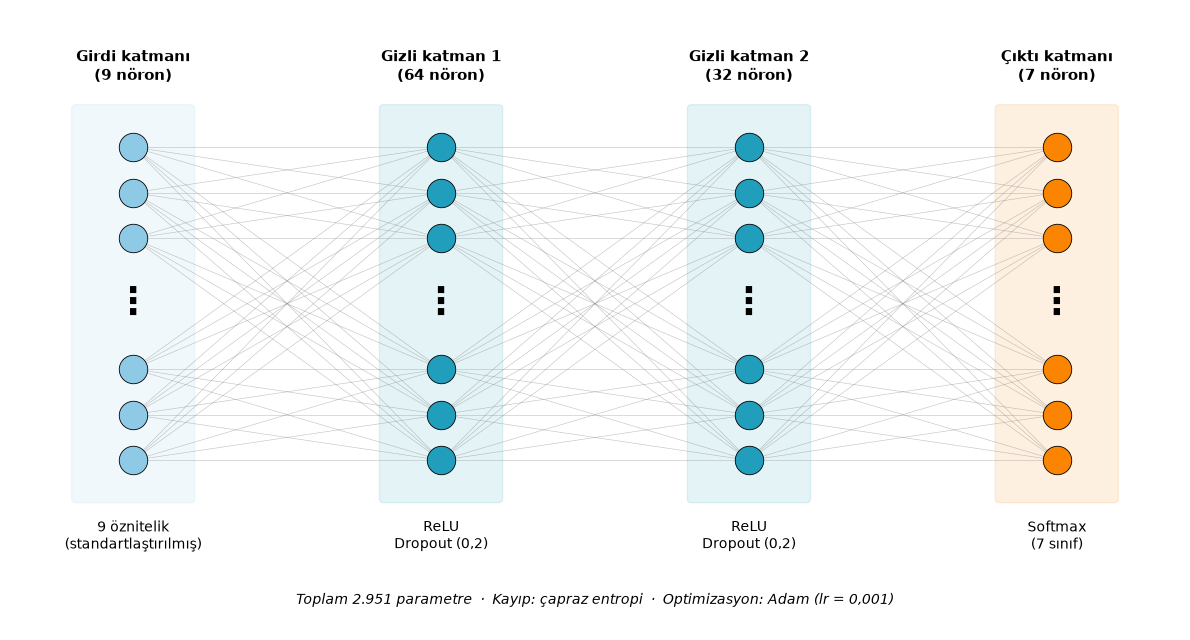

In [3]:
import matplotlib.pyplot as plt
from matplotlib.patches import FancyBboxPatch

katmanlar = [("Girdi katmanı", 9, "9 öznitelik\n(standartlaştırılmış)"),
             ("Gizli katman 1", 64, "ReLU\nDropout (0,2)"),
             ("Gizli katman 2", 32, "ReLU\nDropout (0,2)"),
             ("Çıktı katmanı", 7, "Softmax\n(7 sınıf)")]
x_konum = [0, 3, 6, 9]
renkler = ["#8ecae6", "#219ebc", "#219ebc", "#fb8500"]
y_ust = [2.4, 1.7, 1.0]          # üstte 3 nöron
y_alt = [-1.0, -1.7, -2.4]       # altta 3 nöron, arada "⋮"

fig, ax = plt.subplots(figsize=(12, 6.5))
noktalar = []
for (ad, n, aciklama), x, renk in zip(katmanlar, x_konum, renkler):
    ys = y_ust + y_alt
    noktalar.append([(x, y) for y in ys])
    ax.add_patch(FancyBboxPatch((x - 0.55, -3.0), 1.1, 6.0, boxstyle="round,pad=0.05",
                                fc=renk, alpha=0.12, ec=renk, zorder=0))
    ax.scatter([x] * len(ys), ys, s=420, c=renk, edgecolors="black", linewidths=0.6, zorder=3)
    ax.text(x, 0, "⋮", ha="center", va="center", fontsize=26, weight="bold", zorder=4)
    ax.text(x, 3.35, f"{ad}\n({n} nöron)", ha="center", va="bottom", fontsize=11, weight="bold")
    ax.text(x, -3.3, aciklama, ha="center", va="top", fontsize=10)

for sol, sag in zip(noktalar[:-1], noktalar[1:]):   # katmanlar arası bağlantılar
    for (x1, y1) in sol:
        for (x2, y2) in sag:
            ax.plot([x1, x2], [y1, y2], color="gray", lw=0.4, alpha=0.5, zorder=1)

ax.text(4.5, -4.6, "Toplam 2.951 parametre  ·  Kayıp: çapraz entropi  ·  Optimizasyon: Adam (lr = 0,001)",
        ha="center", fontsize=10, style="italic")
ax.set_xlim(-1.2, 10.2); ax.set_ylim(-5, 4.5); ax.axis("off")
plt.tight_layout()
plt.savefig("sekiller/G3_model_mimarisi.png", dpi=300)
plt.show()

seed   42, batch   16 → doğruluk 0.9992, F1 0.8337, 3.42 sn/epoch
seed   42, batch   32 → doğruluk 0.9992, F1 0.7896, 1.66 sn/epoch
seed   42, batch   64 → doğruluk 0.9991, F1 0.8427, 1.01 sn/epoch
seed   42, batch  128 → doğruluk 0.9979, F1 0.6341, 0.68 sn/epoch
seed   42, batch  256 → doğruluk 0.9974, F1 0.6931, 0.53 sn/epoch
seed   42, batch  512 → doğruluk 0.9968, F1 0.6327, 0.45 sn/epoch
seed   42, batch 1024 → doğruluk 0.9960, F1 0.5611, 0.43 sn/epoch
seed    1, batch   16 → doğruluk 0.9989, F1 0.8572, 2.92 sn/epoch
seed    1, batch   32 → doğruluk 0.9989, F1 0.8662, 1.62 sn/epoch
seed    1, batch   64 → doğruluk 0.9985, F1 0.8480, 1.00 sn/epoch
seed    1, batch  128 → doğruluk 0.9983, F1 0.7884, 0.67 sn/epoch
seed    1, batch  256 → doğruluk 0.9977, F1 0.7203, 0.53 sn/epoch
seed    1, batch  512 → doğruluk 0.9965, F1 0.6035, 0.45 sn/epoch
seed    1, batch 1024 → doğruluk 0.9961, F1 0.5578, 0.43 sn/epoch
seed    7, batch   16 → doğruluk 0.9990, F1 0.8105, 3.01 sn/epoch
seed    7,

,Test doğruluğu,Test macro F1,Ort. epoch süresi (sn)
Batch size,,,
16.0,0.9990 ± 0.0002,0.836 ± 0.042,3.04 ± 0.22
32.0,0.9989 ± 0.0002,0.841 ± 0.046,1.63 ± 0.02
64.0,0.9987 ± 0.0003,0.798 ± 0.049,1.00 ± 0.01
128.0,0.9983 ± 0.0003,0.742 ± 0.070,0.67 ± 0.00
256.0,0.9976 ± 0.0003,0.706 ± 0.045,0.53 ± 0.00
512.0,0.9968 ± 0.0002,0.638 ± 0.022,0.45 ± 0.01
1024.0,0.9961 ± 0.0001,0.536 ± 0.029,0.43 ± 0.01


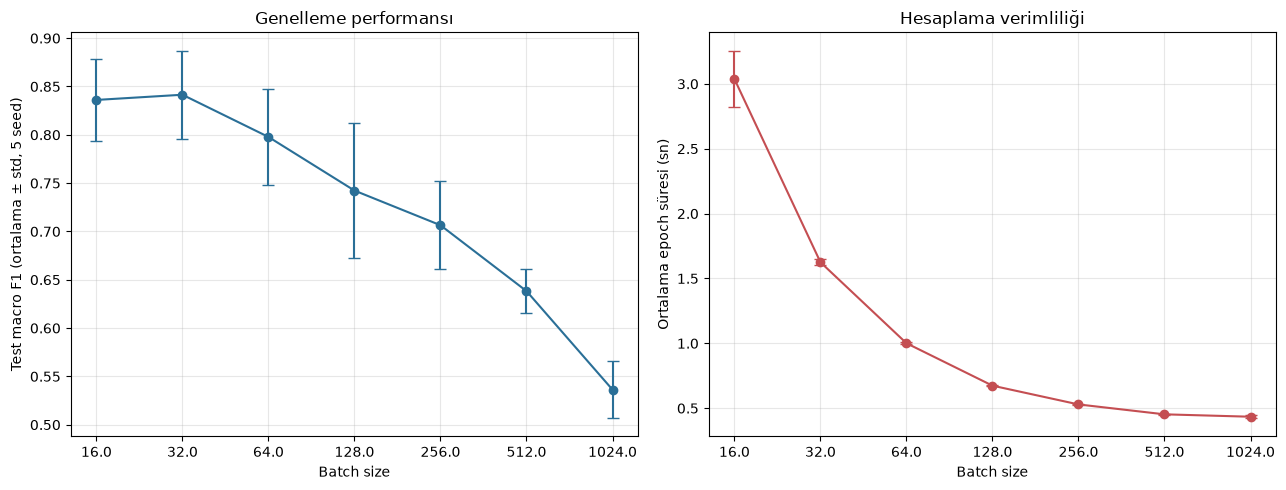

In [4]:
import os, time, random
import numpy as np, pandas as pd, torch, torch.nn as nn
import matplotlib.pyplot as plt
from torch.utils.data import TensorDataset, DataLoader
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import f1_score

# --- Veri (önceki hücrelerle aynı hazırlık) ---
sutunlar = [f"A{i}" for i in range(1, 10)] + ["sinif"]
egitim = pd.read_csv("data/shuttle.trn", sep=r"\s+", header=None, names=sutunlar)
test = pd.read_csv("data/shuttle.tst", sep=r"\s+", header=None, names=sutunlar)
X, y = egitim[sutunlar[:-1]].values, egitim["sinif"].values - 1
X_test, y_test = test[sutunlar[:-1]].values, test["sinif"].values - 1
X_train, X_val, y_train, y_val = train_test_split(X, y, test_size=0.2, stratify=y, random_state=42)
olcek = StandardScaler().fit(X_train)
Xtr = torch.tensor(olcek.transform(X_train), dtype=torch.float32); ytr = torch.tensor(y_train)
Xte = torch.tensor(olcek.transform(X_test), dtype=torch.float32)

class MLP(nn.Module):
    def __init__(self):
        super().__init__()
        self.ag = nn.Sequential(nn.Linear(9, 64), nn.ReLU(), nn.Dropout(0.2),
                                nn.Linear(64, 32), nn.ReLU(), nn.Dropout(0.2), nn.Linear(32, 7))
    def forward(self, x): return self.ag(x)

def egit_seed(batch_size, seed, epoch_sayisi=50):
    random.seed(seed); np.random.seed(seed); torch.manual_seed(seed)
    yukleyici = DataLoader(TensorDataset(Xtr, ytr), batch_size=batch_size, shuffle=True,
                           generator=torch.Generator().manual_seed(seed))
    model = MLP(); opt = torch.optim.Adam(model.parameters(), lr=1e-3); kayip_fn = nn.CrossEntropyLoss()
    t0 = time.perf_counter()
    for _ in range(epoch_sayisi):
        model.train()
        for xb, yb in yukleyici:
            opt.zero_grad(); kayip_fn(model(xb), yb).backward(); opt.step()
    sure = time.perf_counter() - t0
    model.eval()
    with torch.no_grad():
        tahmin = model(Xte).argmax(1).numpy()
    return (tahmin == y_test).mean(), f1_score(y_test, tahmin, average="macro", zero_division=0), sure / epoch_sayisi

# --- Deney: 5 seed x 7 batch size (kaldığı yerden devam eder) ---
dosya = "tablolar/coklu_seed_ham.csv"
sonuc = pd.read_csv(dosya) if os.path.exists(dosya) else pd.DataFrame(columns=["seed", "batch", "dogruluk", "f1", "epoch_sure"])
for seed in [42, 1, 7, 123, 2024]:
    for bs in [16, 32, 64, 128, 256, 512, 1024]:
        if ((sonuc["seed"] == seed) & (sonuc["batch"] == bs)).any():
            continue
        d, f, s = egit_seed(bs, seed)
        sonuc.loc[len(sonuc)] = [seed, bs, d, f, s]
        sonuc.to_csv(dosya, index=False)
        print(f"seed {seed:>4}, batch {bs:>4} → doğruluk {d:.4f}, F1 {f:.4f}, {s:.2f} sn/epoch")

# --- T6b: ortalama ± standart sapma ---
ozet = sonuc.groupby("batch").agg(dogruluk_ort=("dogruluk", "mean"), dogruluk_std=("dogruluk", "std"),
                                  f1_ort=("f1", "mean"), f1_std=("f1", "std"),
                                  sure_ort=("epoch_sure", "mean"), sure_std=("epoch_sure", "std"))
t6b = pd.DataFrame({
    "Test doğruluğu": [f"{m:.4f} ± {s:.4f}" for m, s in zip(ozet.dogruluk_ort, ozet.dogruluk_std)],
    "Test macro F1": [f"{m:.3f} ± {s:.3f}" for m, s in zip(ozet.f1_ort, ozet.f1_std)],
    "Ort. epoch süresi (sn)": [f"{m:.2f} ± {s:.2f}" for m, s in zip(ozet.sure_ort, ozet.sure_std)],
}, index=ozet.index.rename("Batch size"))
display(t6b)
t6b.to_csv("tablolar/T6b_coklu_seed_ozet.csv", encoding="utf-8-sig")

# --- G6b: hata çubuklu karşılaştırma ---
fig, axes = plt.subplots(1, 2, figsize=(13, 5))
x = ozet.index.values
axes[0].errorbar(x, ozet.f1_ort, yerr=ozet.f1_std, fmt="o-", capsize=4, color="#2a6f97")
axes[0].set_ylabel("Test macro F1 (ortalama ± std, 5 seed)"); axes[0].set_title("Genelleme performansı")
axes[1].errorbar(x, ozet.sure_ort, yerr=ozet.sure_std, fmt="o-", capsize=4, color="#c44e52")
axes[1].set_ylabel("Ortalama epoch süresi (sn)"); axes[1].set_title("Hesaplama verimliliği")
for ax in axes:
    ax.set_xscale("log", base=2); ax.set_xticks(x); ax.set_xticklabels(x)
    ax.set_xlabel("Batch size"); ax.grid(alpha=0.3)
plt.tight_layout()
plt.savefig("sekiller/G6b_coklu_seed.png", dpi=300)
plt.show()

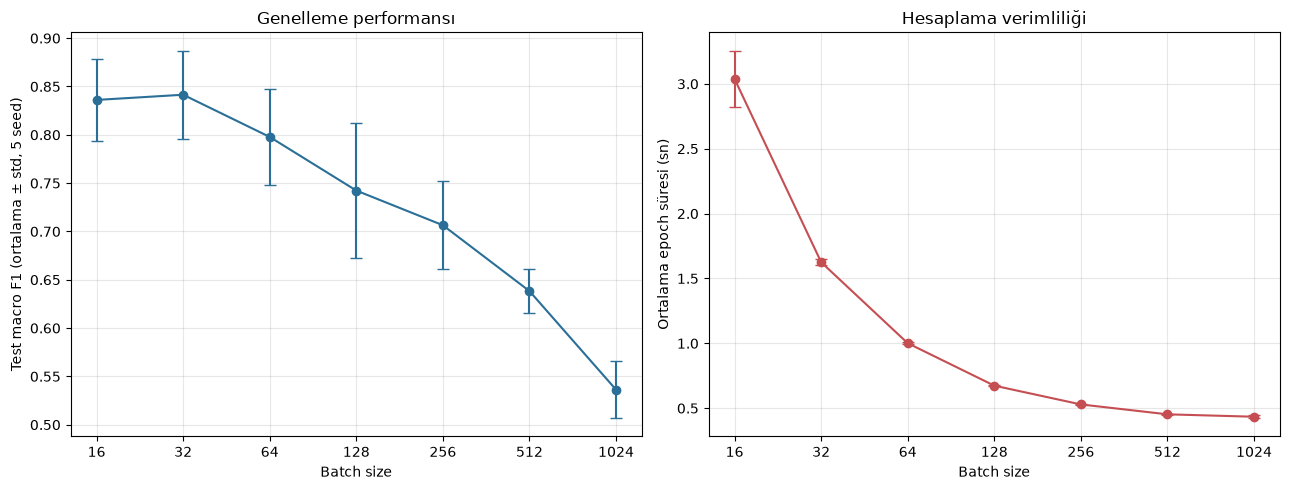

In [5]:
d = pd.read_csv("tablolar/coklu_seed_ham.csv")
ozet = d.groupby(d["batch"].astype(int)).agg(f1_ort=("f1", "mean"), f1_std=("f1", "std"),
                                             sure_ort=("epoch_sure", "mean"), sure_std=("epoch_sure", "std"))
fig, axes = plt.subplots(1, 2, figsize=(13, 5))
x = ozet.index.values
axes[0].errorbar(x, ozet.f1_ort, yerr=ozet.f1_std, fmt="o-", capsize=4, color="#2a6f97")
axes[0].set_ylabel("Test macro F1 (ortalama ± std, 5 seed)"); axes[0].set_title("Genelleme performansı")
axes[1].errorbar(x, ozet.sure_ort, yerr=ozet.sure_std, fmt="o-", capsize=4, color="#c44e52")
axes[1].set_ylabel("Ortalama epoch süresi (sn)"); axes[1].set_title("Hesaplama verimliliği")
for ax in axes:
    ax.set_xscale("log", base=2); ax.set_xticks(x); ax.set_xticklabels(x)
    ax.set_xlabel("Batch size"); ax.grid(alpha=0.3)
plt.tight_layout(); plt.savefig("sekiller/G6b_coklu_seed.png", dpi=300); plt.show()